> **Obs:** detta är den ursprungliga genomgången av en *kortsiktig* mean reversion-strategi, med samma steg som i `modeling_example.ipynb`.
> Själva testerna av om datan mean revertar finns nu i `mean_reversion_simple.ipynb`. Använd den här notebooken som mall när du ska bygga och utvärdera en strategi.

# Mean reversion – samma upplägg som modeling_example

**Idé (i en mening):** om ett pris har rört sig mycket åt ett håll de senaste dagarna, tenderar det att gå tillbaka en del.
→ Sälj (short) efter en uppgång, köp (long) efter en nedgång.

Vi testar idén med exakt samma steg som i `modeling_example.ipynb`:

1. Ladda priser, räkna avkastning och normalisera med volatilitet
2. **Finns mönstret i datan?** Mät autokorrelation och jämför med slumpad (blandad) data
3. Bygg strategin
4. Räkna modellens avkastning
5. Utvärdera med nyckeltal (Sharpe, kostnader, fördröjning)
6. Testa för framåtblickande fusk (look-ahead bias)
7. Riskjustera
8. Slutsats

*Skillnaden mot trend:* trend letar efter **positiv** autokorrelation (rörelser fortsätter), mean reversion letar efter **negativ** (rörelser går tillbaka).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

notebook_file = globals().get("__vsc_ipynb_file__")
NOTEBOOK_DIR = Path(notebook_file).resolve().parent if notebook_file else Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))

from evaluation import calc_key_figures, plot_key_figures

DATE = "AsOfDate"

## 1. Ladda priser, avkastning och normalisering (identiskt med modeling_example)

In [2]:
prices = pl.read_csv(NOTEBOOK_DIR / "example_prices.csv", try_parse_dates=True).rename({"dates": DATE})
instruments = [c for c in prices.columns if c != DATE]

ret = prices.select(DATE, pl.col(instruments).diff())
vol = ret.select(DATE, pl.col(instruments).pow(2).rolling_mean(100, min_samples=10).sqrt().shift(1))
norm_ret = ret.select(DATE, *[(pl.col(c) / vol[c]).fill_nan(None).alias(c) for c in instruments])

print(norm_ret.select(pl.col(instruments).std()))

shape: (1, 5)
┌──────────┬─────────┬──────────┬──────────┬──────────┐
│ diamonds ┆ butter  ┆ cars     ┆ cucumber ┆ bananas  │
│ ---      ┆ ---     ┆ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64     ┆ f64      ┆ f64      ┆ f64      │
╞══════════╪═════════╪══════════╪══════════╪══════════╡
│ 1.022204 ┆ 1.01673 ┆ 1.020913 ┆ 1.015677 ┆ 1.024953 │
└──────────┴─────────┴──────────┴──────────┴──────────┘


## 2. Finns mönstret i datan?

### 2a. Block-autokorrelation (samma test som i modeling_example)
Vi delar upp avkastningen i block om K dagar och mäter korrelationen mellan ett block och nästa.
För mean reversion vill vi se **negativa** värden, och de ska ligga **utanför** det blå bandet, som visar hur stora värden ren slump ger (blandad data, ±2 standardavvikelser).

Vi tittar på korta block (1–20 dagar), eftersom mean reversion typiskt är ett kortsiktigt fenomen.

shape: (10, 3)
┌────────────┬──────────┬────────────────────┐
│ block_size ┆ autocorr ┆ slumpgräns (2 std) │
│ ---        ┆ ---      ┆ ---                │
│ i64        ┆ f64      ┆ f64                │
╞════════════╪══════════╪════════════════════╡
│ 1          ┆ 0.002    ┆ 0.011              │
│ 2          ┆ 0.011    ┆ 0.014              │
│ 3          ┆ -0.0     ┆ 0.017              │
│ 4          ┆ -0.008   ┆ 0.018              │
│ 5          ┆ -0.008   ┆ 0.02               │
│ 6          ┆ -0.005   ┆ 0.023              │
│ 7          ┆ 0.002    ┆ 0.026              │
│ 8          ┆ 0.008    ┆ 0.029              │
│ 9          ┆ 0.015    ┆ 0.03               │
│ 10         ┆ 0.024    ┆ 0.031              │
└────────────┴──────────┴────────────────────┘


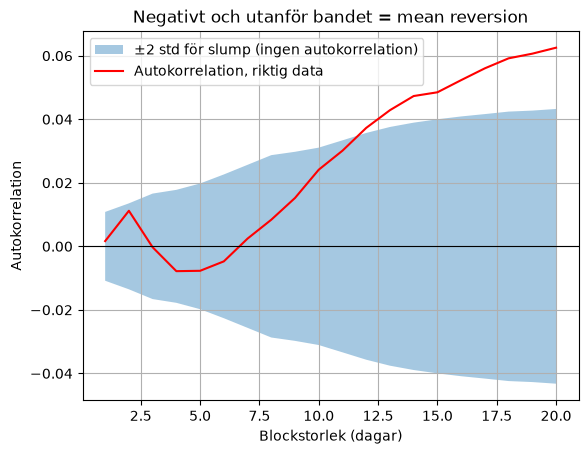

In [3]:
def calc_block_ac(ret: pl.DataFrame, max_block_size: int) -> pl.DataFrame:
    # Samma funktion som i modeling_example
    cols = [c for c in ret.columns if c != DATE]
    cumulative = np.cumsum(ret.select(cols).drop_nulls().to_numpy(), axis=0)

    def offset_correlation(size: int, offset: int) -> np.ndarray:
        indices = np.arange(0, len(cumulative), size) - offset
        blocks = np.diff(cumulative[indices[indices >= 0]], axis=0)
        previous = blocks[:-1] - blocks[:-1].mean(axis=0)
        following = blocks[1:] - blocks[1:].mean(axis=0)
        return (previous * following).sum(axis=0) / np.sqrt(
            (previous**2).sum(axis=0) * (following**2).sum(axis=0)
        )

    rows = [
        np.mean([offset_correlation(size, offset) for offset in range(1, size + 1)], axis=0)
        for size in range(1, max_block_size + 1)
    ]
    return pl.DataFrame(np.asarray(rows), schema=cols).insert_column(
        0, pl.Series("block_size", range(1, max_block_size + 1))
    )


def shuffled_autocorrelations(ret, max_block_size, samples, *, rng):
    return np.column_stack([
        calc_block_ac(
            ret.sample(fraction=1.0, shuffle=True, seed=int(rng.integers(2**32))), max_block_size
        ).select(pl.mean_horizontal(pl.exclude("block_size"))).to_series().to_numpy()
        for _ in range(samples)
    ])


max_block = 20
autocorrs = calc_block_ac(norm_ret, max_block)
mean_ac = autocorrs.select(pl.mean_horizontal(pl.col(instruments))).to_series()
std_shuffled = shuffled_autocorrelations(norm_ret, max_block, 50, rng=np.random.default_rng(1)).std(axis=1, ddof=1)

fig, ax = plt.subplots()
ax.fill_between(autocorrs["block_size"].to_numpy(), 2 * std_shuffled, -2 * std_shuffled,
                alpha=0.4, label="±2 std för slump (ingen autokorrelation)")
ax.plot(autocorrs["block_size"].to_numpy(), mean_ac.to_numpy(), color="r", label="Autokorrelation, riktig data")
ax.axhline(0, color="k", linewidth=0.8)
ax.set_ylabel("Autokorrelation")
ax.set_xlabel("Blockstorlek (dagar)")
ax.set_title("Negativt och utanför bandet = mean reversion")
ax.legend()
ax.grid()

print(pl.DataFrame({"block_size": autocorrs["block_size"], "autocorr": mean_ac.round(3),
                    "slumpgräns (2 std)": (2 * std_shuffled).round(3)}).head(10))

### 2b. Direkt test av just vår signal (tar hänsyn till handelsfördröjningen)
Block-testet ovan jämför block som ligger **direkt efter varandra**. Men vi kan inte handla direkt: en position som bestäms dag t tjänar sin första avkastning dag **t+2**.

Därför testar vi också själva signalen: korrelerar *"minus summan av de senaste L dagarnas avkastning"* med avkastningen **från dag t+2** och framåt?
Samma slumpjämförelse: vi blandar dagarnas ordning 50 gånger och ser hur stora korrelationer slumpen ger.

In [4]:
def mr_signal(ret: pl.DataFrame, lookback: int) -> pl.DataFrame:
    # Mean reversion: motsatt tecken mot den senaste rörelsen
    return ret.select(DATE, -pl.col(instruments).rolling_sum(lookback).sign())


def signal_score(signal: pl.DataFrame, ret: pl.DataFrame, horizon: int) -> float:
    vol = ret.select(pl.col(instruments).pow(2).rolling_mean(100, min_samples=10).sqrt())
    # summan av avkastningen dag t+2 ... t+1+horizon, i volatilitetsenheter
    fut = ret.select([(pl.col(c).reverse().rolling_sum(horizon).reverse().shift(-2) / vol[c]).alias(c)
                      for c in instruments])
    return float(np.nanmean([
        pl.DataFrame({"s": signal[c], "f": fut[c]}).drop_nulls().select(pl.corr("s", "f")).item()
        for c in instruments
    ]))


def signal_test(lookback: int, ret: pl.DataFrame, horizon: int, n_shuffle: int = 50, seed: int = 1):
    real = signal_score(mr_signal(ret, lookback), ret, horizon)
    rng = np.random.default_rng(seed)
    fake = []
    for _ in range(n_shuffle):
        shuffled = ret.select(DATE, pl.col(instruments).sample(fraction=1.0, shuffle=True,
                                                               seed=int(rng.integers(2**32))))
        fake.append(signal_score(mr_signal(shuffled, lookback), shuffled, horizon))
    return real, 2 * np.std(fake, ddof=1)


rows = []
for lb in [2, 3, 5, 10, 20]:
    real, limit = signal_test(lb, ret, horizon=lb)
    rows.append({"lookback": lb, "korrelation": round(real, 4), "slumpgräns (±)": round(limit, 4),
                 "tolkning": "JA, mean reversion" if real > limit
                             else "NEJ, motsatt håll (= trend)" if real < -limit else "nej, slump"})
signal_table = pl.DataFrame(rows)
signal_table

lookback,korrelation,slumpgräns (±),tolkning
i64,f64,f64,str
2,0.0028,0.0142,"""nej, slump"""
3,0.0039,0.0153,"""nej, slump"""
5,0.003,0.0199,"""nej, slump"""
10,-0.0289,0.0224,"""NEJ, motsatt håll (= trend)"""
20,-0.0517,0.0352,"""NEJ, motsatt håll (= trend)"""


## 3. Bygg strategin
Spegelbild av trendmodellen, med två skillnader:
- **Kort fönster** (5 dagar i stället för 50)
- **Minustecken**: short efter uppgång, long efter nedgång

Positionen skalas med volatiliteten precis som förut. Bara data till och med dag t används.

In [5]:
def mean_reversion_model(ret: pl.DataFrame, lookback: int = 5, vol_window: int = 100) -> pl.DataFrame:
    cols = [c for c in ret.columns if c != DATE]
    vol = ret.select(DATE, pl.col(cols).pow(2).rolling_sum(vol_window, min_samples=vol_window // 2).sqrt())
    signal = ret.select(DATE, -pl.col(cols).rolling_sum(lookback).sign())   # <-- enda skillnaden mot trend
    return signal.select(DATE, *[(pl.col(c) / vol[c]).fill_nan(None).alias(c) for c in cols])


pos = mean_reversion_model(ret)

## 4. Modellens avkastning (positionerna förskjuts 2 dagar, som förut)

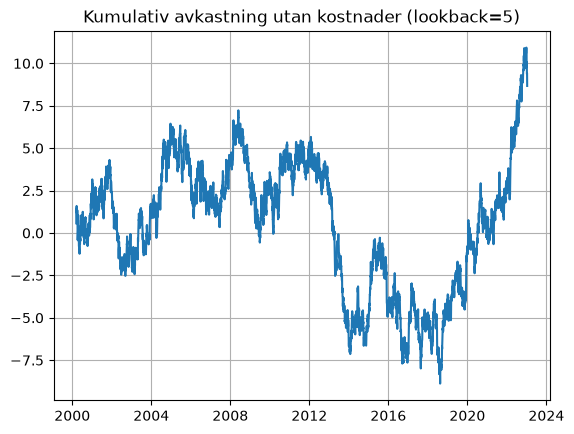

In [6]:
def model_returns(positions: pl.DataFrame, ret: pl.DataFrame) -> pl.DataFrame:
    cols = [c for c in positions.columns if c != DATE]
    gross = positions.select(DATE, *[(pl.col(c).shift(2) * ret[c]).alias(c) for c in cols])
    return gross.filter(~pl.all_horizontal(pl.col(cols).is_null())).select(
        DATE, pl.sum_horizontal(pl.col(cols)).alias("model_return")
    )


model_ret = model_returns(pos, ret)
fig, ax = plt.subplots()
ax.plot(model_ret[DATE].to_numpy(), model_ret["model_return"].cum_sum().to_numpy())
ax.set_title("Kumulativ avkastning utan kostnader (lookback=5)")
ax.grid()

## 5. Utvärdering med nyckeltal
`sharpe_ex_slippage` = före kostnader, `sharpe` = efter kostnader, `sharpe_1d_lag` = om vi handlar en dag sent.

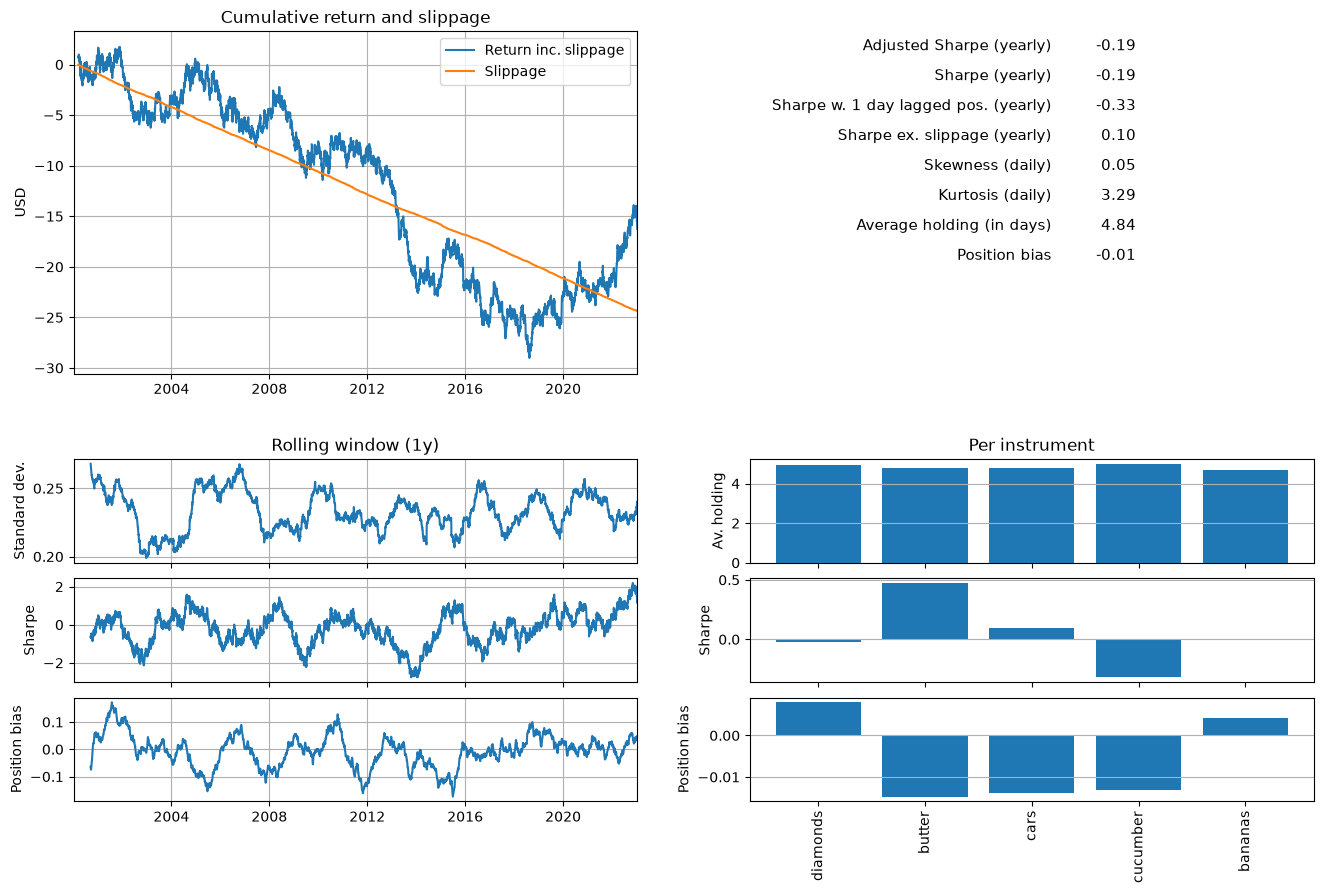

In [7]:
plot_key_figures(pos, prices)

In [8]:
KEYS = ["sharpe_ex_slippage", "sharpe", "sharpe_1d_lag", "adjusted_sharpe", "av_holding", "skewness", "kurtosis"]
calc_key_figures(pos, prices, key_figures=KEYS)

{'sharpe': -0.1903042935353058,
 'sharpe_1d_lag': -0.32919953241410854,
 'sharpe_ex_slippage': 0.10137290879234544,
 'av_holding': 4.8401334610180635,
 'skewness': 0.047551585106861714,
 'kurtosis': 3.292496756683853,
 'adjusted_sharpe': -0.1899332789402283}

### Är det bara en dålig parameter? Prova flera fönster
Ett äkta fenomen ska synas i ett *område* av parametrar, inte bara i en enda.
Som jämförelse tar vi med trendmodellen från modeling_example.

In [9]:
def trend_model_vectorized(ret: pl.DataFrame, trend_window: int = 50, vol_window: int = 100) -> pl.DataFrame:
    cols = [c for c in ret.columns if c != DATE]
    vol = ret.select(DATE, pl.col(cols).pow(2).rolling_sum(vol_window, min_samples=vol_window // 2).sqrt())
    signal = ret.select(DATE, pl.col(cols).rolling_sum(trend_window).sign())
    return signal.select(DATE, *[(pl.col(c) / vol[c]).fill_nan(None).alias(c) for c in cols])


def summary(name, p):
    kf = calc_key_figures(p, prices, key_figures=KEYS)
    return {"modell": name, **{k: round(v, 2) for k, v in kf.items()}}


rows = [summary(f"mean reversion, lookback={lb}", mean_reversion_model(ret, lookback=lb)) for lb in [2, 3, 5, 10, 20]]
rows.append(summary("TREND (modeling_example)", trend_model_vectorized(ret)))
pl.DataFrame(rows)

modell,sharpe,sharpe_1d_lag,sharpe_ex_slippage,av_holding,skewness,kurtosis,adjusted_sharpe
str,f64,f64,f64,f64,f64,f64,f64
"""mean reversion, lookback=2""",-0.58,-0.19,-0.11,3.01,0.05,3.16,-0.57
"""mean reversion, lookback=3""",-0.56,-0.13,-0.19,3.71,0.03,3.2,-0.56
"""mean reversion, lookback=5""",-0.19,-0.33,0.1,4.84,0.05,3.29,-0.19
"""mean reversion, lookback=10""",-0.12,-0.35,0.08,6.81,0.01,3.18,-0.12
"""mean reversion, lookback=20""",-0.56,-0.59,-0.42,9.6,-0.01,3.4,-0.56
"""TREND (modeling_example)""",0.68,0.64,0.78,15.28,0.06,3.29,0.68


### Kostnadskänslighet
Mean reversion handlar ofta, så kostnader slår hårt. Jämför med trend.

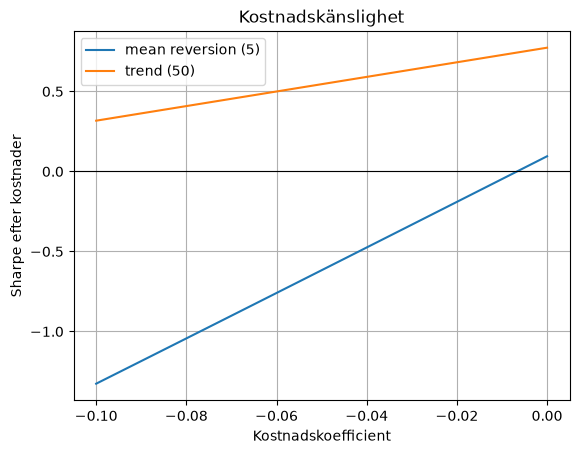

In [10]:
cost_coeffs = np.linspace(0, -0.1, 10)
fig, ax = plt.subplots()
for name, p in [("mean reversion (5)", pos), ("trend (50)", trend_model_vectorized(ret))]:
    s = [calc_key_figures(p, prices, costs=float(c), key_figures=["sharpe"])["sharpe"] for c in cost_coeffs]
    ax.plot(cost_coeffs, s, label=name)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_title("Kostnadskänslighet")
ax.set_ylabel("Sharpe efter kostnader")
ax.set_xlabel("Kostnadskoefficient")
ax.legend()
ax.grid()

### Stabilitet över tid
Fungerar strategin i båda halvorna av historiken?

In [11]:
middle = prices[DATE][prices.height // 2]
rows = []
for lb in [3, 5, 10]:
    p = mean_reversion_model(ret, lookback=lb)
    for label, part in [("första halvan", p.filter(pl.col(DATE) < middle)),
                        ("andra halvan", p.filter(pl.col(DATE) >= middle))]:
        rows.append(summary(f"lookback={lb} | {label}", part))
pl.DataFrame(rows).select("modell", "sharpe_ex_slippage", "sharpe")

modell,sharpe_ex_slippage,sharpe
str,f64,f64
"""lookback=3 | första halvan""",-0.35,-0.74
"""lookback=3 | andra halvan""",-0.01,-0.39
"""lookback=5 | första halvan""",0.11,-0.19
"""lookback=5 | andra halvan""",0.11,-0.18
"""lookback=10 | första halvan""",0.23,0.03
"""lookback=10 | andra halvan""",-0.06,-0.26


## 6. Test för framåtblickande fusk

In [12]:
pos_full = mean_reversion_model(ret)
pos_short = mean_reversion_model(ret.head(ret.height - 20))
comparison = pos_short.join(pos_full, on=DATE, suffix="_full", maintain_order="left")
comparison.select(*[(pl.col(c) - pl.col(f"{c}_full")).abs().sum().alias(c) for c in instruments])

diamonds,butter,cars,cucumber,bananas
f64,f64,f64,f64,f64
0.0,0.0,0.0,0.0,0.0


## 7. Riskjustera
Samma metod som i modeling_example: dela positionerna med strategins rullande risk så att risken blir ungefär 1 och jämnare över tid.

In [13]:
def mean_reversion_model_risk_adjusted(ret: pl.DataFrame, lookback: int = 5, vol_window: int = 100,
                                       risk_window: int = 100) -> pl.DataFrame:
    cols = [c for c in ret.columns if c != DATE]
    positions = mean_reversion_model(ret, lookback, vol_window)
    gross = positions.select(DATE, *[(pl.col(c).shift(2) * ret[c]).alias(c) for c in cols])
    risk = gross.filter(~pl.all_horizontal(pl.col(cols).is_null())).select(
        DATE, pl.sum_horizontal(pl.col(cols)).rolling_std(risk_window, min_samples=20).alias("model_risk")
    )
    aligned = positions.join(risk, on=DATE, how="left", maintain_order="left")
    return aligned.select(DATE, *[(pl.col(c) / pl.col("model_risk")).fill_nan(None).alias(c) for c in cols])


pos_ra = mean_reversion_model_risk_adjusted(ret)
plot_key_figures(pos_ra, prices)
calc_key_figures(pos_ra, prices, key_figures=KEYS)

{'sharpe': -0.1840099118399785,
 'sharpe_1d_lag': -0.31777367230239484,
 'sharpe_ex_slippage': 0.10377433597494685,
 'av_holding': 4.811558366260278,
 'skewness': 0.06090802568821751,
 'kurtosis': 3.4129153543184856,
 'adjusted_sharpe': -0.18355899639318465}

## 8. Slutsats (för `example_prices.csv`)

**Kort mean reversion fungerar inte på den här datan.** Det syns redan i steg 2, och resten av stegen bekräftar det.

| Steg | Resultat |
|---|---|
| 2a. Block-autokorrelation | Värdena för 1–10 dagar ligger nära 0 och **inom slumpbandet**. Ingen negativ autokorrelation att tjäna pengar på. |
| 2b. Signaltest | För 2–5 dagar går signalen inte att skilja från slump. För 10–20 dagar pekar den **åt fel håll**: rörelserna *fortsätter*, vilket är trend, inte reversion. |
| 5. Sharpe före kostnader | Som bäst ≈ 0,1 (lookback 5–10). Med 23 års data är en standardavvikelse för Sharpe ≈ 0,2, så det är brus. |
| 5. Sharpe efter kostnader | **Negativ för alla fönster.** Strategin håller positioner bara 3–10 dagar och betalar mycket i kostnader. Trend (15 dagar) klarar sig mycket bättre. |
| 5. Stabilitet | Resultatet hoppar mellan halvorna (t.ex. lookback 10: +0,23 → −0,06). Inget stabilt mönster. |
| 6. Fusktest | 0 i skillnad, så ingen look-ahead bias. Själva koden är korrekt. |
| 7. Riskjustering | Ändrar nästan ingenting. Riskjustering jämnar ut risken men **skapar ingen edge**. |

**Lärdom om upplägget:** om steg 2 inte visar något mönster lönar det sig sällan att fortsätta. Här hade vi kunnat stanna där.

**Vidare:** `mean_reversion.ipynb` hittar en svag reversion på **lång sikt (80–300 dagar)** som ger ett litet tillskott *ovanpå* trendmodellen.